# Sequence Labeling: Finding Names, Places and Companies (and How to Judge the AI)

In this notebook the computer will **read a French sentence and put a label on every word**:
is it a **person**, a **place**, an **organization**... or nothing?

**Part 1: Live demo**
- type **any French sentence** and watch the entities light up in color
- see the **BIO labels** word by word, and the grammar of each word (**POS**)
- compare two models: **spaCy** (tiny and fast) and **CamemBERT-NER** (a French BERT)

**Part 2: Evaluation**
- why we count **entities**, not words (the *"all O"* trap)
- the **boundary error** that counts twice
- **F1 per type**: the average hides the weak spots
- an **ethics test**: does the model find *Fatima Zahra* as well as *Pierre*?

## What is sequence labeling?

Imagine a teacher with three highlighters: **blue** for people, **pink** for places, **green** for organizations.
She reads the sentence and colors every word. That is NER (Named Entity Recognition).

| Task | Question | Example |
|---|---|---|
| **Classification** (notebook 01) | "What is the label of the **whole text**?" | "Ce film est nul" ➜ négatif |
| **Sequence labeling** (this notebook) | "What is the label of **each word**?" | "Ali vit à Fès" ➜ Ali = PER, Fès = LOC |

## Step 0: Prepare your computer (one time only)

```bash
python -m venv .venv
source .venv/bin/activate            # Windows: .venv\Scripts\Activate.ps1
pip install ipykernel transformers torch sentencepiece protobuf spacy seqeval matplotlib pandas
python -m spacy download fr_core_news_sm
```

Then in VS Code: **Select Kernel** > **Python Environments** > **.venv**. The cell below does the install for you.

In [ ]:
%pip install -q transformers torch sentencepiece protobuf spacy seqeval matplotlib pandas
import sys
!{sys.executable} -m spacy download fr_core_news_sm -q


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('fr_core_news_sm')


## Step 1: Import the tools

- `transformers`: the **CamemBERT-NER** model (a BERT trained on French)
- `spacy`: a fast language toolbox with a small French model
- `seqeval`: the **official way** to score NER (it counts entities, not words)
- `pandas`, `matplotlib`, `IPython.display`: tables, charts and colored text

In [2]:
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

import spacy
from transformers import pipeline
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score, accuracy_score
from seqeval.metrics.sequence_labeling import get_entities

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"PER": "#0090ea", "LOC": "#eb04a3", "ORG": "#21b35a", "MISC": "#f5a524"}
print("All tools loaded.")

/home/mdev/Dev/school/nlp_notebooks/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All tools loaded.


## Step 2: Settings (the control panel)

| Setting | What it does |
|---|---|
| `BERT_MODEL` | The big brain: CamemBERT fine-tuned for French NER (~440 MB, downloaded once) |
| `SPACY_MODEL` | The small brain: spaCy's French model (~15 MB) |
| `MIN_SCORE` | Ignore BERT entities with a confidence below this value |
| `LIVE_DEMO` | `True` lets you type your own sentences in Step 7 |

In [3]:
BERT_MODEL  = "Jean-Baptiste/camembert-ner"
SPACY_MODEL = "fr_core_news_sm"
MIN_SCORE   = 0.5
LIVE_DEMO   = True

## Step 3: Load the two models

- **spaCy** (`fr_core_news_sm`): a small classic network. Like a **pocket dictionary**: fast, light, less precise.
- **CamemBERT-NER**: a French BERT (the architecture of slide 12, with **one label per word** instead of one per sentence). Like a **full encyclopedia**.

In [4]:
bert_ner = pipeline("ner", model=BERT_MODEL, aggregation_strategy="simple")
nlp = spacy.load(SPACY_MODEL)

def folder_size_mb(package):
    import importlib.util, os
    spec = importlib.util.find_spec(package)
    if not spec or not spec.submodule_search_locations:
        return float("nan")
    root = list(spec.submodule_search_locations)[0]
    return sum(os.path.getsize(os.path.join(d, f)) for d, _, fs in os.walk(root) for f in fs) / 1e6

BERT_PARAMS_M = bert_ner.model.num_parameters() / 1e6
SPACY_MB = folder_size_mb(SPACY_MODEL)
if np.isnan(SPACY_MB):
    SPACY_MB = 15.0   # typical size of fr_core_news_sm
print(f"CamemBERT-NER: {BERT_PARAMS_M:.0f} million parameters")
print(f"spaCy {SPACY_MODEL}: about {SPACY_MB:.0f} MB on disk")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4615.73it/s]


CamemBERT-NER: 110 million parameters
spaCy fr_core_news_sm: about 27 MB on disk


## Step 4: How do we label words? The BIO code

An entity can have **several words** (*Université Mohammed V*). So each word gets a small code:

| Code | Meaning | Example |
|---|---|---|
| **B-**TYPE | **B**eginning of an entity | Université ➜ **B-ORG** |
| **I-**TYPE | **I**nside the same entity | Mohammed ➜ **I-ORG**, V ➜ **I-ORG** |
| **O** | **O**utside: not an entity | étudie ➜ **O** |

```
Mohamed   étudie   à   l'   Université   Mohammed   V      .
 B-PER      O      O   O     B-ORG        I-ORG    I-ORG  O
```

The model gives a label to every word, then we **glue** B + I together to get the entities.

## Step 5: Helpers

- `predict_bert(text)` and `predict_spacy(text)`: return the entities as `(type, start, end, text)`
- `show_entities(text, ents, title)`: colors the entities like highlighters
- `to_bio(words, ents)`: converts the entities into BIO labels, one per word

In [5]:
def predict_bert(text):
    ents = []
    for e in bert_ner(text):
        if e["score"] < MIN_SCORE:
            continue
        s, en = e["start"], e["end"]
        while s < en and text[s] == " ":   # some tokenizers include the space before the word
            s += 1
        ents.append((e["entity_group"], s, en, text[s:en]))
    return ents


def predict_spacy(text):
    return [(e.label_, e.start_char, e.end_char, e.text) for e in nlp(text).ents]


def show_entities(text, ents, title):
    html, last = "", 0
    for typ, s, e, word in sorted(ents, key=lambda x: x[1]):
        c = COLORS.get(typ, "#999")
        html += text[last:s] + (f'<span style="background:{c};color:white;border-radius:8px;padding:2px 6px;margin:0 2px;font-weight:bold">'
                                f'{text[s:e]} <sup style="font-size:10px">{typ}</sup></span>')
        last = e
    html += text[last:]
    return (f'<div style="font-family:sans-serif;margin:6px 0"><div style="font-size:12px;color:#666;font-weight:bold">{title}</div>'
            f'<div style="border:3px solid #100f0d;border-radius:12px;padding:10px 14px;background:#fff;font-size:18px;line-height:2">{html}</div></div>')


def tokenize(text):
    # words + their character positions (punctuation and l' are separate words)
    return [(m.group(0), m.start(), m.end()) for m in re.finditer(r"\w+'|\w+(?:-\w+)*|[^\w\s]", text)]


def to_bio(spans, ents):
    tags, prev = [], None
    for _, ws, we in spans:
        hit = next((e for e in ents if ws < e[2] and we > e[1]), None)
        if hit is None:
            tags.append("O"); prev = None
        else:
            tags.append(("I-" if hit == prev else "B-") + hit[0]); prev = hit
    return tags


def bio_table(text):
    spans = tokenize(text)
    words = [w for w, _, _ in spans]
    bert_tags = to_bio(spans, predict_bert(text))
    pos = {t.text: t.pos_ for t in nlp(text)}
    def cell(tag):
        c = "#eee" if tag == "O" else COLORS.get(tag[2:], "#999")
        fg = "#100f0d" if tag == "O" else "white"
        return f'<td style="background:{c};color:{fg};padding:4px 8px;text-align:center;font-weight:bold;border-radius:6px">{tag}</td>'
    head = "".join(f'<td style="padding:4px 8px;text-align:center;font-weight:bold;border:2px solid #100f0d;border-radius:6px">{w}</td>' for w in words)
    return ('<table style="border-collapse:separate;border-spacing:4px;font-family:sans-serif;font-size:14px">'
            f'<tr><th style="text-align:right;padding-right:8px">word</th>{head}</tr>'
            f'<tr><th style="text-align:right;padding-right:8px">NER (BIO)</th>{"".join(cell(t) for t in bert_tags)}</tr>'
            f'<tr><th style="text-align:right;padding-right:8px">POS</th>{"".join(f"<td style=text-align:center;color:#555>{pos.get(w, chr(8211))}</td>" for w in words)}</tr></table>')


def compare(text):
    display(HTML(show_entities(text, predict_spacy(text), "spaCy (small)")
                 + show_entities(text, predict_bert(text), "CamemBERT-NER (big)")
                 + bio_table(text)))

legend = " ".join(f'<span style="background:{c};color:white;border-radius:6px;padding:2px 8px;font-family:sans-serif;font-weight:bold">{t}</span>'
                  for t, c in COLORS.items())
display(HTML(f"<div>Legend: {legend} &nbsp; PER = person, LOC = place, ORG = organization, MISC = other</div>"))

## Step 6: First tests

Before looking: which words would **you** color, and with which color?

In [6]:
EXAMPLES = [
    "Mohamed Doukkani étudie à l'INPT à Rabat.",
    "Le Raja a battu le Wydad hier soir à Casablanca.",
    "Fatima Zahra Bennani travaille chez OCP à Khouribga.",
    "Washington a signé la loi, puis il est rentré à Washington.",   # same word, two meanings!
]
for s in EXAMPLES:
    compare(s)

word,Mohamed,Doukkani,étudie,à,l',INPT,à,Rabat,.
NER (BIO),B-PER,I-PER,O,O,O,B-ORG,O,B-LOC,O
POS,PROPN,PROPN,VERB,ADP,DET,NOUN,ADP,NOUN,PUNCT


word,Le,Raja,a,battu,le,Wydad,hier,soir,à,Casablanca,.
NER (BIO),O,B-ORG,O,O,O,B-ORG,O,O,O,B-LOC,O
POS,DET,PROPN,AUX,VERB,DET,NOUN,ADV,NOUN,ADP,PROPN,PUNCT


word,Fatima,Zahra,Bennani,travaille,chez,OCP,à,Khouribga,.
NER (BIO),B-PER,I-PER,I-PER,O,O,B-ORG,O,B-LOC,O
POS,PROPN,PROPN,PROPN,VERB,ADP,PROPN,ADP,PROPN,PUNCT


word,Washington,a,signé,la,loi,",",puis,il,est,rentré,à,Washington,.
NER (BIO),B-LOC,O,O,O,O,O,O,O,O,O,O,B-LOC,O
POS,PROPN,AUX,VERB,DET,NOUN,PUNCT,CCONJ,PRON,AUX,VERB,ADP,PROPN,PUNCT


## Step 7: Your turn (live demo)

Type a French sentence and press **Enter**. Empty line = stop.

Ideas: your own name and city, a football match, a news headline, a sentence with a company and a country.

In [ ]:
if LIVE_DEMO:
    while True:
        sentence = input("Écris une phrase en français (vide = stop) : ").strip()
        if not sentence:
            print("Demo stopped.")
            break
        compare(sentence)

# Part 2: How good is this AI, really?

## Step 8: Our test set (the "answer sheet")

To evaluate, we need sentences where a **human** has already written the correct label of every word.
Here are 16 French sentences annotated by hand, with Moroccan names, cities, clubs and companies.

In [7]:
GOLD = [
    ("Mohamed Doukkani étudie à l' INPT à Rabat .",                 "B-PER I-PER O O O B-ORG O B-LOC O"),
    ("Le Raja a battu le Wydad à Casablanca .",                      "O B-ORG O O O B-ORG O B-LOC O"),
    ("Fatima Zahra Bennani travaille chez OCP à Khouribga .",        "B-PER I-PER I-PER O O B-ORG O B-LOC O"),
    ("Emmanuel Macron a rencontré Aziz Akhannouch à Paris .",        "B-PER I-PER O O B-PER I-PER O B-LOC O"),
    ("Youssef a acheté un téléphone Samsung à Marjane .",           "B-PER O O O O B-ORG O B-ORG O"),
    ("L' Université Mohammed V se trouve à Rabat .",                "O B-ORG I-ORG I-ORG O O O B-LOC O"),
    ("Hier , Sara et Amine sont partis à Chefchaouen .",            "O O B-PER O B-PER O O O B-LOC O"),
    ("La Banque mondiale a publié un rapport sur le Maroc .",       "O B-ORG I-ORG O O O O O O B-LOC O"),
    ("Le TGV Al Boraq relie Tanger à Casablanca en deux heures .",  "O B-MISC I-MISC I-MISC O B-LOC O B-LOC O O O O"),
    ("Achraf Hakimi joue au Paris Saint-Germain .",                 "B-PER I-PER O O B-ORG I-ORG O"),
    ("Nous avons visité Marrakech avec Karim et Leila .",           "O O O B-LOC O B-PER O B-PER O"),
    ("Orange Maroc lance une nouvelle offre à Agadir .",            "B-ORG I-ORG O O O O O B-LOC O"),
    ("Le professeur Rachid Alami enseigne à Fès .",                 "O O B-PER I-PER O O B-LOC O"),
    ("Google et Microsoft ont ouvert des bureaux à Dakhla .",       "B-ORG O B-ORG O O O O O B-LOC O"),
    ("Ilham et Mehdi ont regardé la Coupe du monde au café .",      "B-PER O B-PER O O O B-MISC I-MISC I-MISC O O O"),
    ("Le roi Mohammed VI a inauguré le port de Tanger Med .",       "O O B-PER I-PER O O O O O B-LOC I-LOC O"),
]

def rebuild(words):
    # join words into a natural sentence and remember where each word is
    text, spans = "", []
    for w in words:
        if text and not text.endswith("'") and w not in ".,!?":
            text += " "
        spans.append((w, len(text), len(text) + len(w)))
        text += w
    return text, spans

DATA = []
for sent, tags in GOLD:
    words, tags = sent.split(), tags.split()
    assert len(words) == len(tags), sent
    text, spans = rebuild(words)
    DATA.append({"text": text, "spans": spans, "gold": tags})

n_ent = sum(len(get_entities(d["gold"])) for d in DATA)
n_tok = sum(len(d["gold"]) for d in DATA)
n_o = sum(t == "O" for d in DATA for t in d["gold"])
print(f"{len(DATA)} sentences, {n_tok} words, {n_ent} entities.")
print(f"{n_o / n_tok:.0%} of the words are 'O' (not an entity). Remember this number!")
display(HTML(show_entities(DATA[0]["text"], [(t, DATA[0]["spans"][s][1], DATA[0]["spans"][e][2], "") for t, s, e in get_entities(DATA[0]["gold"])], "Example of the answer sheet (gold)")))

16 sentences, 154 words, 42 entities.
61% of the words are 'O' (not an entity). Remember this number!


## Step 9: The metrics on a tiny example (the one of the slides)

Truth: **Université Mohammed V** (3 words). The model found only **Université Mohammed**.

$$\text{Token accuracy}=\frac{1}{N}\sum_{i=1}^{N}\mathbb{1}[\hat y_i=y_i]\qquad P=\frac{|E_{pred}\cap E_{gold}|}{|E_{pred}|}\qquad R=\frac{|E_{pred}\cap E_{gold}|}{|E_{gold}|}$$

$N$ = number of words, $y_i$ = true label, $\hat y_i$ = predicted label, $E$ = set of entities. An entity is correct only if **type and borders** are exact.

In [8]:
gold = [["B-PER", "O", "O", "O", "B-ORG", "I-ORG", "I-ORG", "O", "B-LOC"]]
pred = [["B-PER", "O", "O", "O", "B-ORG", "I-ORG", "O",     "O", "B-LOC"]]
words = ["Mohamed", "étudie", "à", "l'", "Université", "Mohammed", "V", "de", "Rabat"]

display(pd.DataFrame([words, gold[0], pred[0]], index=["word", "truth", "model"]).style.apply(
    lambda r: ["background:#ffd6d6" if gold[0][i] != pred[0][i] else "" for i in range(len(r))], axis=1).hide(axis="columns"))

print(f"Token accuracy      : {accuracy_score(gold, pred):.1%}   (8 words out of 9 are right)")
print(f"Entity precision    : {precision_score(gold, pred):.1%}   (2 of the 3 found entities are right)")
print(f"Entity recall       : {recall_score(gold, pred):.1%}   (2 of the 3 true entities are found)")
print(f"Entity F1           : {f1_score(gold, pred):.1%}")
print("\nOne missing word ('V') = one wrong entity. The token accuracy looks great, the F1 tells the truth.")

word,Mohamed,étudie,à,l',Université,Mohammed,V,de,Rabat
truth,B-PER,O,O,O,B-ORG,I-ORG,I-ORG,O,B-LOC
model,B-PER,O,O,O,B-ORG,I-ORG,O,O,B-LOC


Token accuracy      : 88.9%   (8 words out of 9 are right)
Entity precision    : 66.7%   (2 of the 3 found entities are right)
Entity recall       : 66.7%   (2 of the 3 true entities are found)
Entity F1           : 66.7%

One missing word ('V') = one wrong entity. The token accuracy looks great, the F1 tells the truth.


## Step 10: Evaluate the two models on the 16 sentences

For each model: predict, convert to BIO, then let `seqeval` count the entities.

In [9]:
def run(model_fn):
    preds, t0 = [], time.perf_counter()
    for d in DATA:
        preds.append(to_bio(d["spans"], model_fn(d["text"])))
    return preds, (time.perf_counter() - t0) * 1000 / len(DATA)

GOLD_TAGS = [d["gold"] for d in DATA]
results = {}
for name, fn in [("spaCy", predict_spacy), ("CamemBERT-NER", predict_bert)]:
    preds, ms = run(fn)
    results[name] = {"preds": preds, "ms": ms}
    print(f"===== {name}  ({ms:.0f} ms per sentence) =====")
    print(classification_report(GOLD_TAGS, preds, zero_division=0))

summary = pd.DataFrame({name: {"Token accuracy": accuracy_score(GOLD_TAGS, r["preds"]),
                               "Entity F1 (micro)": f1_score(GOLD_TAGS, r["preds"], zero_division=0),
                               "Entity F1 (macro)": f1_score(GOLD_TAGS, r["preds"], average="macro", zero_division=0)}
                        for name, r in results.items()})
display(summary.style.format("{:.1%}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1, axis=None))

===== spaCy  (9 ms per sentence) =====
              precision    recall  f1-score   support

         LOC       0.57      0.93      0.70        14
        MISC       0.00      0.00      0.00         2
         ORG       1.00      0.58      0.74        12
         PER       0.75      0.43      0.55        14

   micro avg       0.62      0.62      0.62        42
   macro avg       0.58      0.49      0.50        42
weighted avg       0.72      0.62      0.63        42

===== CamemBERT-NER  (55 ms per sentence) =====
              precision    recall  f1-score   support

         LOC       0.82      1.00      0.90        14
        MISC       0.33      0.50      0.40         2
         ORG       0.90      0.75      0.82        12
         PER       0.92      0.86      0.89        14

   micro avg       0.84      0.86      0.85        42
   macro avg       0.74      0.78      0.75        42
weighted avg       0.86      0.86      0.85        42



,spaCy,CamemBERT-NER
Token accuracy,83.8%,92.2%
Entity F1 (micro),61.9%,84.7%
Entity F1 (macro),49.6%,75.3%


### The comparison in three charts: speed, size, score

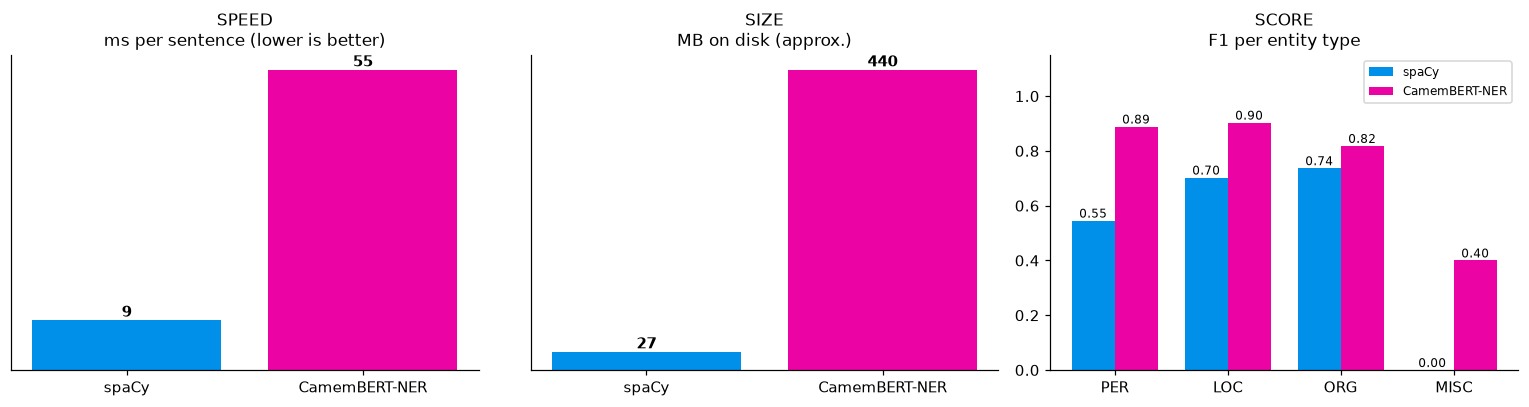

Look at MISC: rare and vague entities are always the hardest. The global F1 hides it.


In [10]:
types = ["PER", "LOC", "ORG", "MISC"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
names = list(results)
for ax, vals, title, fmt in [
    (axes[0], [results[n]["ms"] for n in names], "SPEED\nms per sentence (lower is better)", "%.0f"),
    (axes[1], [SPACY_MB, BERT_PARAMS_M * 4], "SIZE\nMB on disk (approx.)", "%.0f"),
]:
    bars = ax.bar(names, vals, color=["#0090ea", "#eb04a3"]); ax.bar_label(bars, fmt=fmt, fontweight="bold"); ax.set_title(title, fontsize=11); ax.set_yticks([])

x = np.arange(len(types)); w = 0.38
for k, (n, c) in enumerate(zip(names, ["#0090ea", "#eb04a3"])):
    rep = classification_report(GOLD_TAGS, results[n]["preds"], output_dict=True, zero_division=0)
    vals = [rep.get(t, {}).get("f1-score", 0) for t in types]
    bars = axes[2].bar(x + (k - .5) * w, vals, w, color=c, label=n); axes[2].bar_label(bars, fmt="%.2f", fontsize=8)
axes[2].set_xticks(x, types); axes[2].set_ylim(0, 1.15); axes[2].legend(fontsize=8, loc="upper right"); axes[2].set_title("SCORE\nF1 per entity type", fontsize=11)
plt.tight_layout(); plt.show()
print("Look at MISC: rare and vague entities are always the hardest. The global F1 hides it.")

## Step 11: Trap 1 — the model that finds nothing

A model that answers **O** for every word. Most words are O... so its token accuracy looks good.

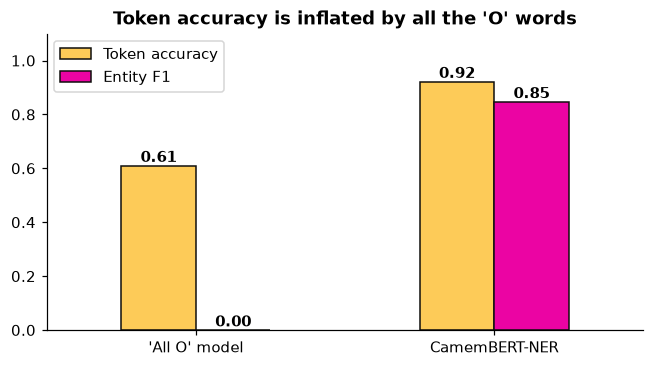

The 'All O' model finds 0 entities but gets 61% token accuracy.


In [11]:
all_o = [["O"] * len(g) for g in GOLD_TAGS]
trap = pd.DataFrame({"'All O' model": {"Token accuracy": accuracy_score(GOLD_TAGS, all_o), "Entity F1": f1_score(GOLD_TAGS, all_o, zero_division=0)},
                     "CamemBERT-NER": {"Token accuracy": accuracy_score(GOLD_TAGS, results["CamemBERT-NER"]["preds"]),
                                       "Entity F1": f1_score(GOLD_TAGS, results["CamemBERT-NER"]["preds"], zero_division=0)}})
ax = trap.T.plot.bar(figsize=(7, 3.5), color=["#fdcb58", "#eb04a3"], rot=0, ylim=(0, 1.1), edgecolor="#100f0d")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontweight="bold")
ax.set_title("Token accuracy is inflated by all the 'O' words", fontweight="bold"); plt.show()
print(f"The 'All O' model finds 0 entities but gets {trap.loc['Token accuracy', chr(39) + 'All O' + chr(39) + ' model']:.0%} token accuracy.")

## Step 12: Trap 2 — strict or partial? The border error that counts twice

In **strict** mode (the official CoNLL way), *Université Mohammed* instead of *Université Mohammed V* is
**one false positive + one false negative**. A **partial** score gives credit when the type is right and the words overlap.
Always say which one you report!

In [12]:
def partial_f1(golds, preds):
    tp = n_pred = n_gold = 0
    for g, p in zip(golds, preds):
        ge, pe = get_entities(g), get_entities(p)
        n_pred += len(pe); n_gold += len(ge); used = set()
        for t, s, e in pe:
            for j, (gt, gs, gend) in enumerate(ge):
                if j not in used and t == gt and s <= gend and e >= gs:
                    used.add(j); tp += 1; break
    P = tp / n_pred if n_pred else 0; R = tp / n_gold if n_gold else 0
    return 2 * P * R / (P + R) if P + R else 0

cmp = pd.DataFrame({n: {"Strict F1": f1_score(GOLD_TAGS, r["preds"], zero_division=0), "Partial F1": partial_f1(GOLD_TAGS, r["preds"])}
                    for n, r in results.items()})
display(cmp.style.format("{:.1%}"))

def show_errors(name):
    out = ""
    for d, p in zip(DATA, results[name]["preds"]):
        g_ent, p_ent = set(get_entities(d["gold"])), set(get_entities(p))
        missed, wrong = g_ent - p_ent, p_ent - g_ent
        if missed or wrong:
            words = [w for w, _, _ in d["spans"]]
            fmt = lambda S: ", ".join(f"{' '.join(words[s:e+1])} ({t})" for t, s, e in sorted(S, key=lambda x: x[1])) or "-"
            out += f"<tr><td>{d['text']}</td><td style='color:#d62828'>{fmt(missed)}</td><td style='color:#0090ea'>{fmt(wrong)}</td></tr>"
    display(HTML(f"<h4 style='font-family:sans-serif'>Errors of {name}</h4><table style='font-family:sans-serif;font-size:13px'>"
                 "<tr><th>Sentence</th><th>Missed (FN)</th><th>Wrong (FP)</th></tr>" + (out or "<tr><td>No error!</td></tr>") + "</table>"))

show_errors("CamemBERT-NER")

,spaCy,CamemBERT-NER
Strict F1,61.9%,84.7%
Partial F1,66.7%,91.8%


Sentence,Missed (FN),Wrong (FP)
Youssef a acheté un téléphone Samsung à Marjane.,Marjane (ORG),Marjane (LOC)
Achraf Hakimi joue au Paris Saint-Germain.,Paris Saint-Germain (ORG),Paris Saint-Germain (LOC)
Nous avons visité Marrakech avec Karim et Leila.,Karim (PER),Karim (MISC)
Orange Maroc lance une nouvelle offre à Agadir.,Orange Maroc (ORG),"Orange (ORG), Maroc (LOC)"
Ilham et Mehdi ont regardé la Coupe du monde au café.,Coupe du monde (MISC),la Coupe (MISC)
Le roi Mohammed VI a inauguré le port de Tanger Med.,Mohammed VI (PER),Le roi Mohammed VI (PER)


## Step 13: Ethics test — does the model treat every name the same way?

We put **different first names** in the **same sentences**. If the model is fair, it should find all of them equally well.
This is exactly the idea of slide 31: compute the metric **per group** and look at the gap
$\Delta = |\,\text{rate}_A - \text{rate}_B\,|$.

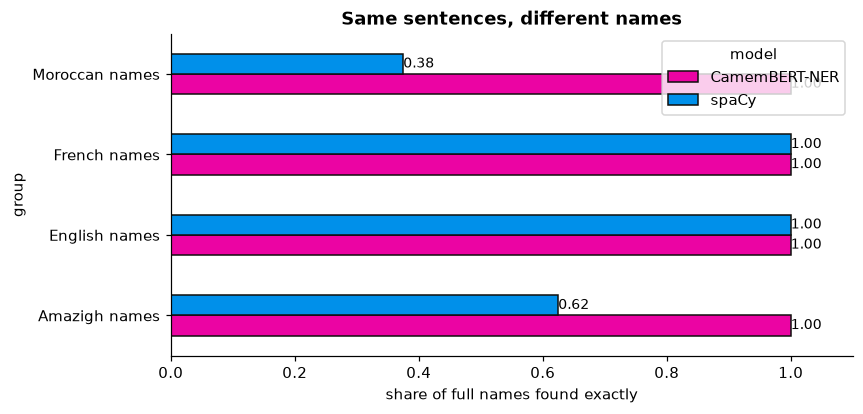

CamemBERT-NER: gap between the best and the worst group = 0%
spaCy: gap between the best and the worst group = 62%
A good global F1 does not prove the model is fair: always test per group.


In [13]:
GROUPS = {
    "French names":   ["Pierre Martin", "Sophie Dubois", "Julien Moreau", "Camille Laurent"],
    "Moroccan names": ["Fatima Zahra Bennani", "Youssef El Amrani", "Khadija Ouazzani", "Mehdi Benjelloun"],
    "Amazigh names":  ["Itto Aït Ouahi", "Massinissa Aït Ali", "Tafsut Ouchen", "Idir Amellal"],
    "English names":  ["Emily Johnson", "Michael Brown", "Sarah Wilson", "James Taylor"],
}
TEMPLATES = ["{} travaille à Casablanca depuis 2019.", "Hier, {} a présenté son projet à l'université.",
             "J'ai rencontré {} au café.", "{} habite à Agadir avec sa famille."]

rows = []
for group, names in GROUPS.items():
    for name in names:
        for tpl in TEMPLATES:
            text = tpl.format(name); s = text.index(name); e = s + len(name)
            for model, fn in [("spaCy", predict_spacy), ("CamemBERT-NER", predict_bert)]:
                ents = [x for x in fn(text) if x[0] == "PER"]
                rows.append({"group": group, "model": model,
                             "exact": any(a == s and b == e for _, a, b, _ in ents),
                             "found": any(a < e and b > s for _, a, b, _ in ents)})
fair = pd.DataFrame(rows).groupby(["group", "model"])["exact"].mean().unstack()
ax = fair.plot.barh(figsize=(8, 3.8), color=["#eb04a3", "#0090ea"], xlim=(0, 1.1), edgecolor="#100f0d")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=9)
ax.set_xlabel("share of full names found exactly"); ax.set_title("Same sentences, different names", fontweight="bold"); plt.show()
for m in fair.columns:
    print(f"{m}: gap between the best and the worst group = {fair[m].max() - fair[m].min():.0%}")
print("A good global F1 does not prove the model is fair: always test per group.")

## Step 14: Three numbers to remember

| | Question | Metric | Trap |
|---|---|---|---|
| **Token accuracy** | How many words have the right label? | right words / all words | Inflated by the many "O" words |
| **Entity F1** | Are the entities found, with exact borders? | 2PR / (P+R) on entities | One missing word = 1 FP + 1 FN (strict) |
| **F1 per type / per group** | Is it good for **every** type and **every** kind of name? | F1 or rate per group | The global average hides the weak spots |

**Which model should I choose?**

| If you need... | Choose |
|---|---|
| Speed, a small computer, millions of documents | **spaCy** small |
| Better quality on names, rare entities, borders | **CamemBERT-NER** |
| Your own types (products, diseases...) | Fine-tune a BERT on your own annotated sentences |

### Things to try
- Add 5 sentences of your own to `GOLD` (with their BIO labels) and rerun Part 2.
- Raise `MIN_SCORE` to `0.9`: precision goes up, recall goes down (like the threshold of notebook 01).
- Add a new group of names in Step 13 (Senegalese, Spanish...).

### Common problems
| Problem | Solution |
|---|---|
| `Can't find model 'fr_core_news_sm'` | Run `python -m spacy download fr_core_news_sm` in the terminal, then restart the kernel |
| `sentencepiece` error | `pip install sentencepiece protobuf`, then restart the kernel |
| An entity is cut strangely | Normal for some tokenizers: the model works on sub-words. Check `MIN_SCORE` |